In [12]:
%pip install -q ultralytics roboflow requests pandas matplotlib pyyaml

In [2]:
from getpass import getpass
from roboflow import Roboflow
from pathlib import Path

rf = Roboflow(api_key="qxtXvMDIIuyyhjit5TTO")

# Проект из указанной ссылки
project = rf.workspace("koer3741-gmail-com").project("watermeteramrv2")

# Скачать версию 1 в формате YOLO
dataset = project.version(1).download(
    "yolov11",
    location="/content/watermeter_dataset"
)

DATASET_DIR = Path("/content/watermeter_dataset")

print("Датасет скачан:", DATASET_DIR)
print("Файлы:", [p.name for p in DATASET_DIR.iterdir()])

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/watermeter_dataset in yolov11:: 100%|██████████| 8524/8524 [00:03<00:00, 2359.96it/s]

Датасет скачан: /content/watermeter_dataset
Файлы: ['README.roboflow.txt', 'README.dataset.txt', 'train', 'test', 'data.yaml', 'valid']


In [3]:
from pathlib import Path
import yaml

yaml_files = list(DATASET_DIR.glob("*.yaml"))
assert yaml_files, "Не найден data.yaml в папке датасета"

DATA_YAML = yaml_files[0]

with open(DATA_YAML, "r", encoding="utf-8") as f:
    data = yaml.safe_load(f)

print("Конфигурация датасета:")
print(yaml.safe_dump(data, allow_unicode=True, sort_keys=False))

print("\nКоличество изображений:")

for split in ("train", "valid", "val", "test"):
    folder = DATASET_DIR / split / "images"
    if folder.exists():
        count = sum(
            1 for p in folder.iterdir()
            if p.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".webp", ".bmp"
            }
        )
        print(f"{split}: {count}")

Конфигурация датасета:
train: ../train/images
val: ../valid/images
test: ../test/images
nc: 12
names:
- '0'
- '1'
- '2'
- '3'
- '4'
- '5'
- '6'
- '7'
- '8'
- '9'
- counter
- liters
roboflow:
  workspace: koer3741-gmail-com
  project: watermeteramrv2
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/koer3741-gmail-com/watermeteramrv2/dataset/1


Количество изображений:
train: 3478
valid: 389
test: 389


In [4]:
from ultralytics import YOLO
from pathlib import Path
import yaml
import torch

# Определяем конфигурацию
DATASET_DIR = Path("/content/watermeter_dataset")
DATA_YAML = next(DATASET_DIR.glob("*.yaml"))

with open(DATA_YAML, "r", encoding="utf-8") as f:
    data = yaml.safe_load(f)

# Абсолютный путь к корню датасета
data["path"] = str(DATASET_DIR)

# Сохраняем исправленную конфигурацию
TRAIN_YAML = DATASET_DIR / "data_train.yaml"

with open(TRAIN_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(data, f, allow_unicode=True, sort_keys=False)

assert torch.cuda.is_available(), (
    "GPU не обнаружена. В Colab выбери среду выполнения с GPU."
)

print("GPU:", torch.cuda.get_device_name(0))
print("Классы:", data["names"])

# Загружаем предобученную YOLO11m
model = YOLO("yolo11m.pt")

# Обучение
results = model.train(
    data=str(TRAIN_YAML),
    epochs=50,
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    patience=10,
    project="/content/runs/watermeter",
    name="yolo11m",
    plots=True,
    seed=42,
    exist_ok=True
)

BEST_MODEL = "/content/runs/watermeter/yolo11m/weights/best.pt"

assert Path(BEST_MODEL).exists(), "Не найден файл best.pt"
print("Обучение завершено. Лучшая модель:", BEST_MODEL)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4
Классы: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'counter', 'liters']
Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/watermeter_dataset/data_train.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, emb

In [5]:
from ultralytics import YOLO
from pathlib import Path

BEST_MODEL = "/content/runs/watermeter/yolo11m/weights/best.pt"
model = YOLO(BEST_MODEL)

if "test" not in data:
    raise RuntimeError(
        "Нет отдельной тестовой выборки. "
        "Проверь экспорт Roboflow или создай test split "
        "до обучения модели."
    )

metrics = model.val(
    data=str(TRAIN_YAML),
    split="test",
    imgsz=640,
    batch=4,
    device=0,
    plots=True,
    project="/content/runs/watermeter",
    name="test_evaluation"
)

map50 = metrics.box.map50
map5095 = metrics.box.map

print(f"mAP@0.5:      {map50:.4f} ({map50 * 100:.2f}%)")
print(f"mAP@0.5:0.95: {map5095:.4f} ({map5095 * 100:.2f}%)")

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,039,284 parameters, 0 gradients, 67.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 32.1±11.3 MB/s, size: 50.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/watermeter_dataset/test/labels... 389 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 389/389 864.6it/s 0.4s
val: New cache created: /content/watermeter_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 98/98 4.8it/s 20.3s
                   all        389       2105      0.952      0.954      0.969      0.569
                     0        162        213      0.877      0.939      0.949       0.53
                     1        108        153      0.901      0.961      0.956      

results.png


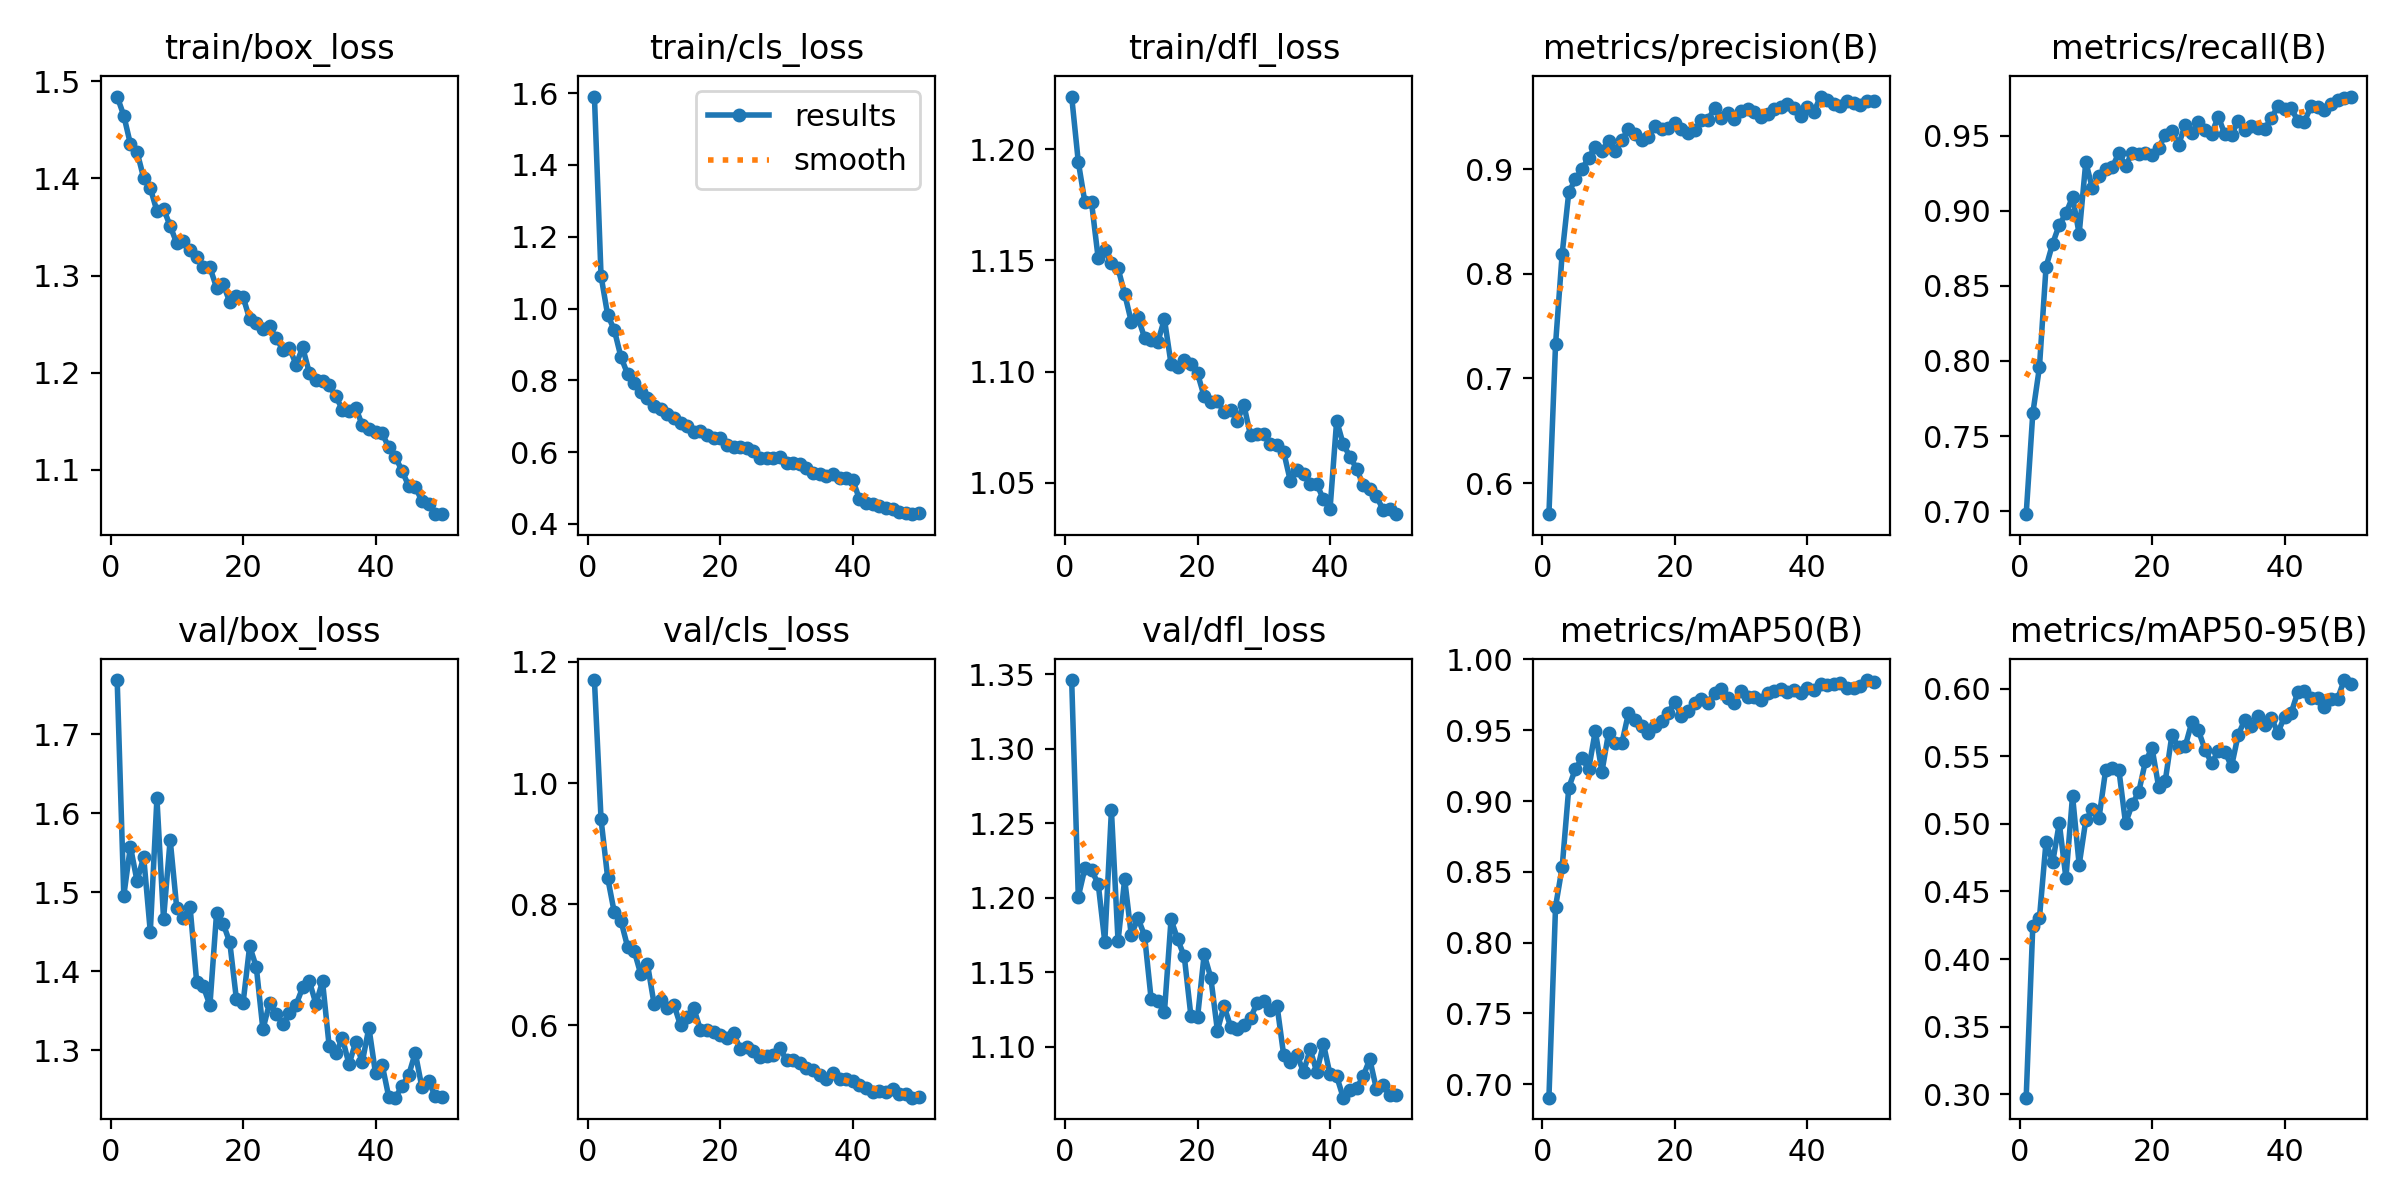

confusion_matrix.png


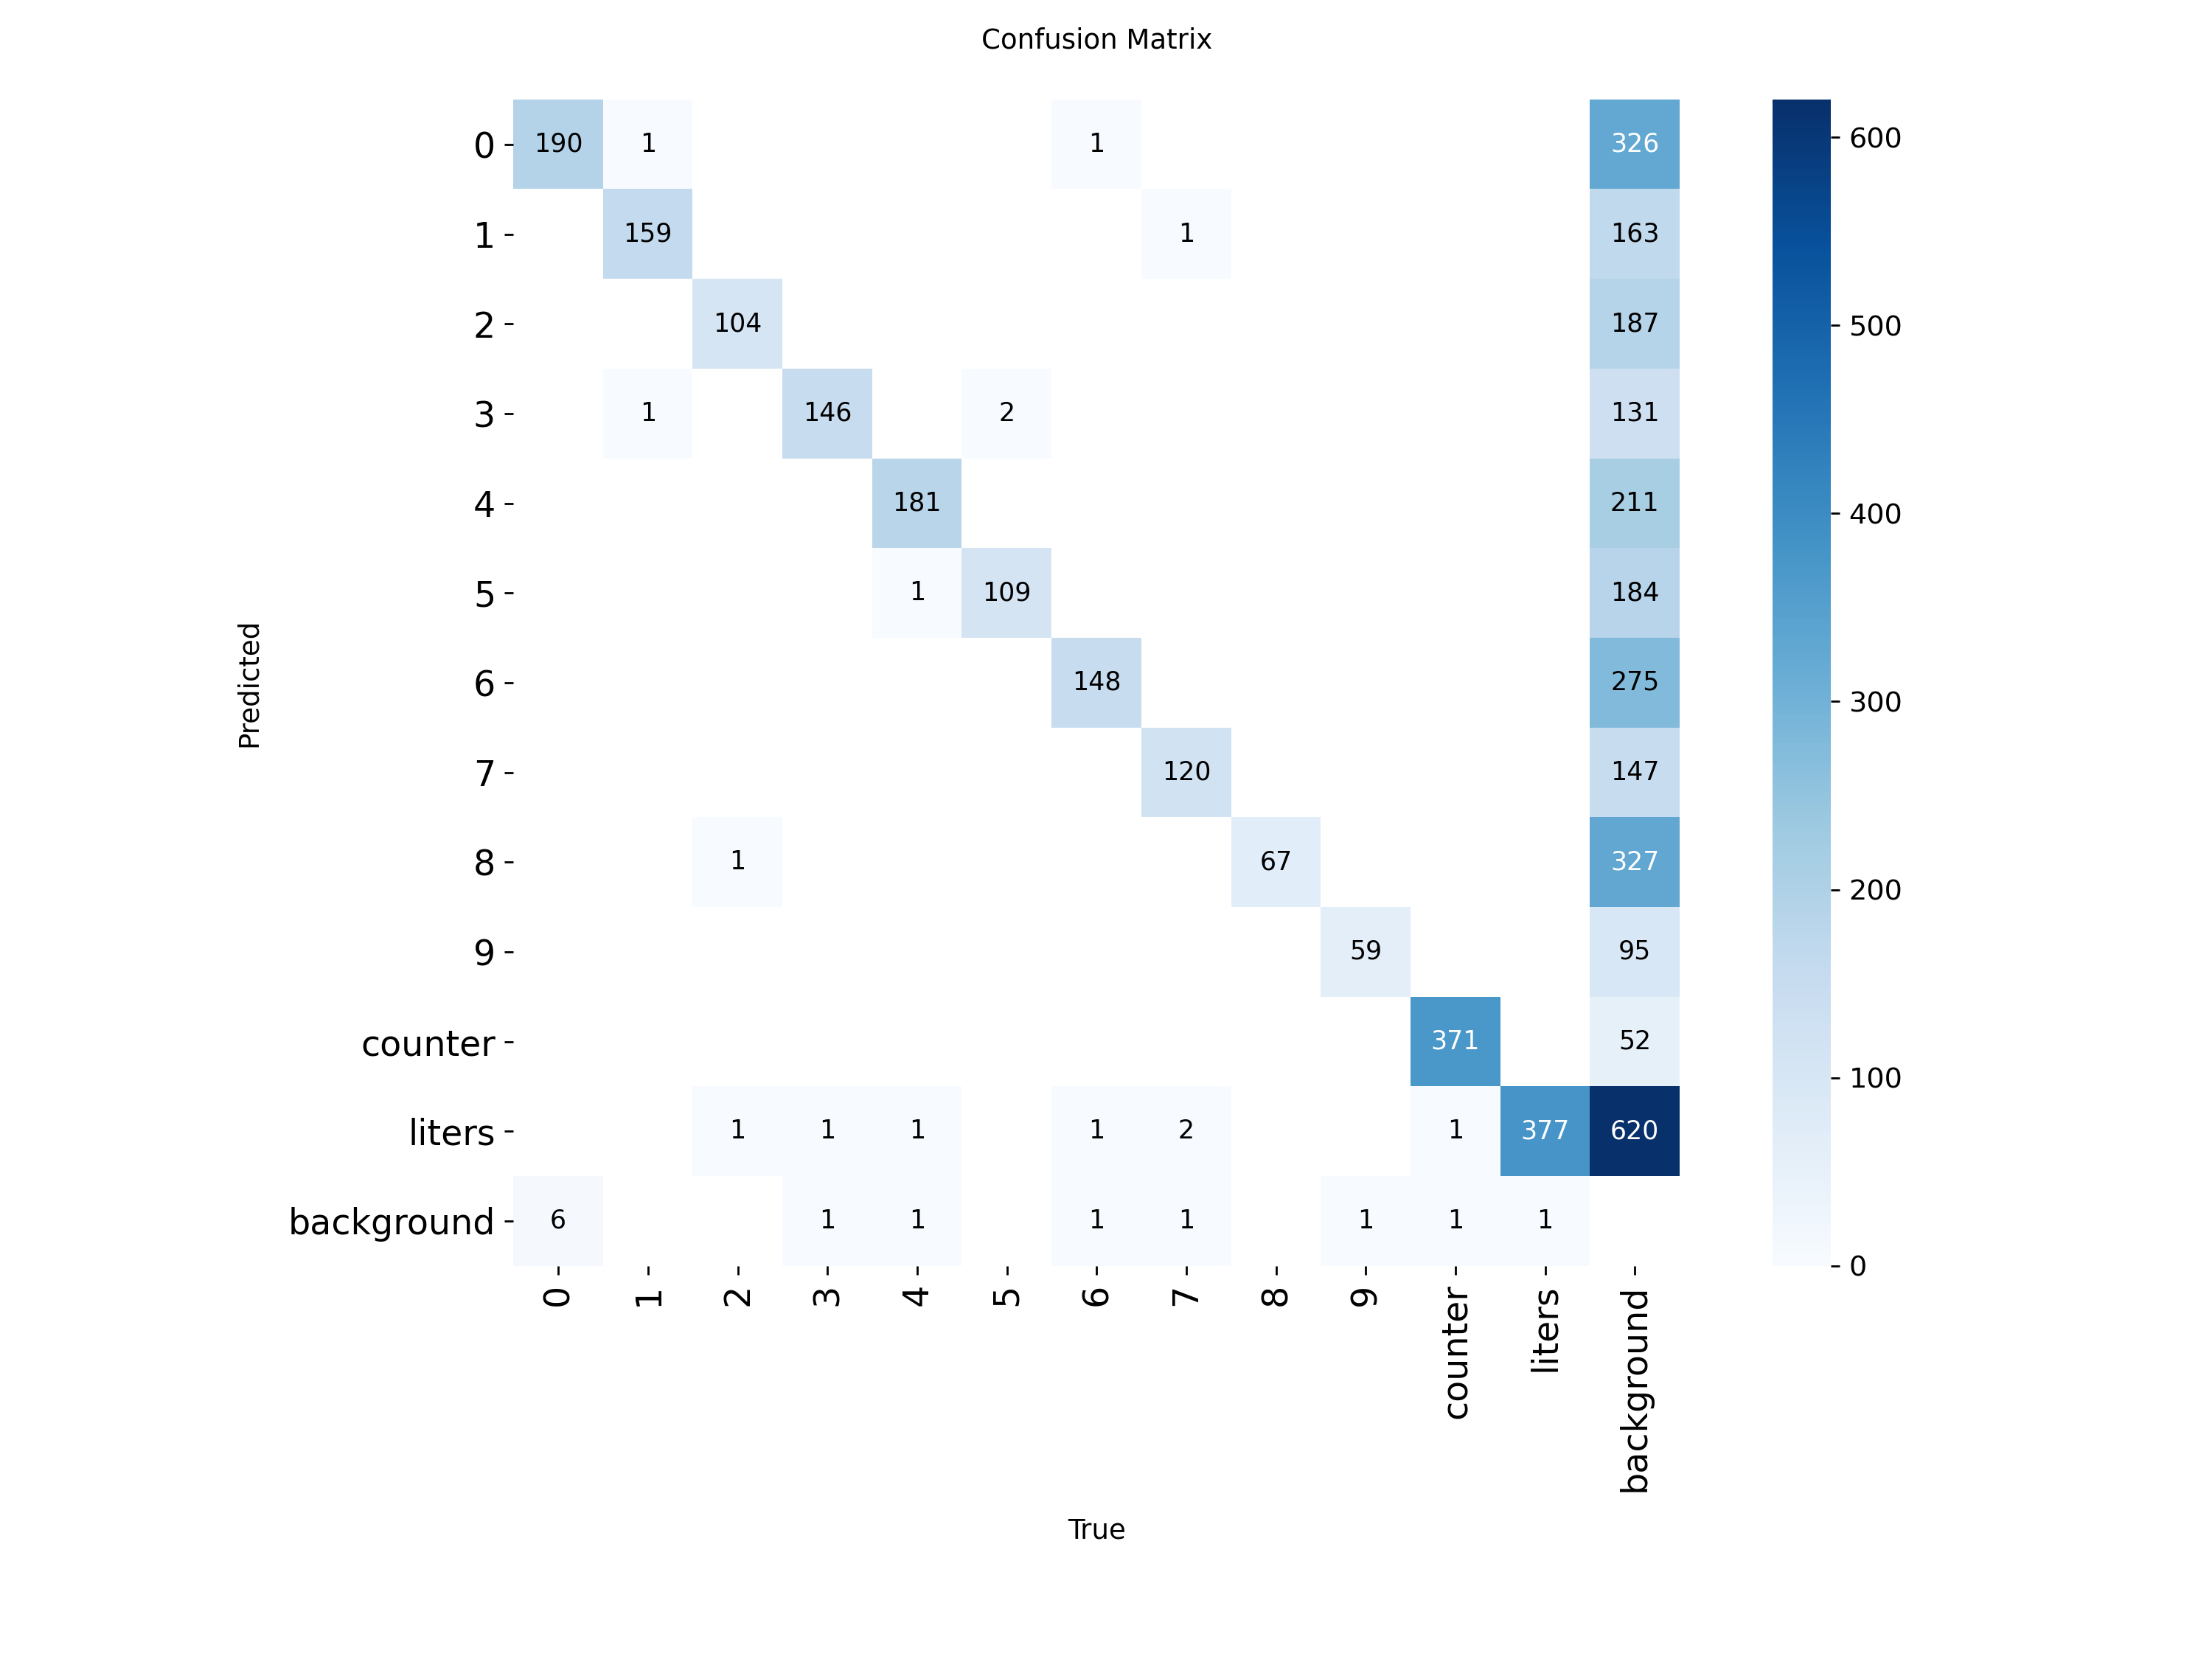

In [6]:
from pathlib import Path
from IPython.display import display, Image

results_dir = Path("/content/runs/watermeter/yolo11m")

for name in [
    "results.png",
    "confusion_matrix.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png"
]:
    path = results_dir / name

    if path.exists():
        print(name)
        display(Image(filename=str(path)))

In [7]:
import shutil
from pathlib import Path
from google.colab import files

archive_path = shutil.make_archive(
    "/content/watermeter_lab_results",
    "zip",
    "/content/runs/watermeter"
)

print("Архив готов:", archive_path)
files.download(archive_path)

Архив готов: /content/watermeter_lab_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
from ultralytics import YOLO

# Загружаем лучшие веса предыдущего обучения
model = YOLO("/content/runs/watermeter/yolo11m/weights/best.pt")

# Дообучаем с аугментацией
model.train(
    data="/content/watermeter_dataset/data.yaml",
    epochs=15,
    imgsz=960,
    batch=4,
    device=0,

    # Аугментация
    degrees=15.0,       # Поворот до ±15°
    translate=0.1,     # Сдвиг изображения
    scale=0.3,         # Изменение масштаба
    fliplr=0.0,        # Не отражать по горизонтали
    flipud=0.0,        # Не отражать по вертикали
    hsv_h=0.015,       # Изменение оттенка
    hsv_s=0.5,         # Изменение насыщенности
    hsv_v=0.3,         # Изменение яркости

    mosaic=0.5,        # Мозаичная аугментация
    mixup=0.0,         # Без смешивания изображений

    name="watermeter_aug"
)

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/watermeter_dataset/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/watermeter/yolo11m/weights/best.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=watermeter_au

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bb10ed49d30>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,  

In [15]:
import shutil
from pathlib import Path
from google.colab import files

archive_path = shutil.make_archive(
    "/content/watermeter_lab_results",
    "zip",
    "/content/runs"
)

print("Архив готов:", archive_path)
files.download(archive_path)

Архив готов: /content/watermeter_lab_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
from google.colab import files

uploaded = files.upload()

Saving IMG_7718.JPG to IMG_7718.JPG



image 1/1 /content/internet_images/IMG_7718.JPG: 640x480 1 2, 2 4s, 1 counter, 1 liters, 76.9ms
Speed: 10.8ms preprocess, 76.9ms inference, 26.6ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/watermeter/internet_predictions


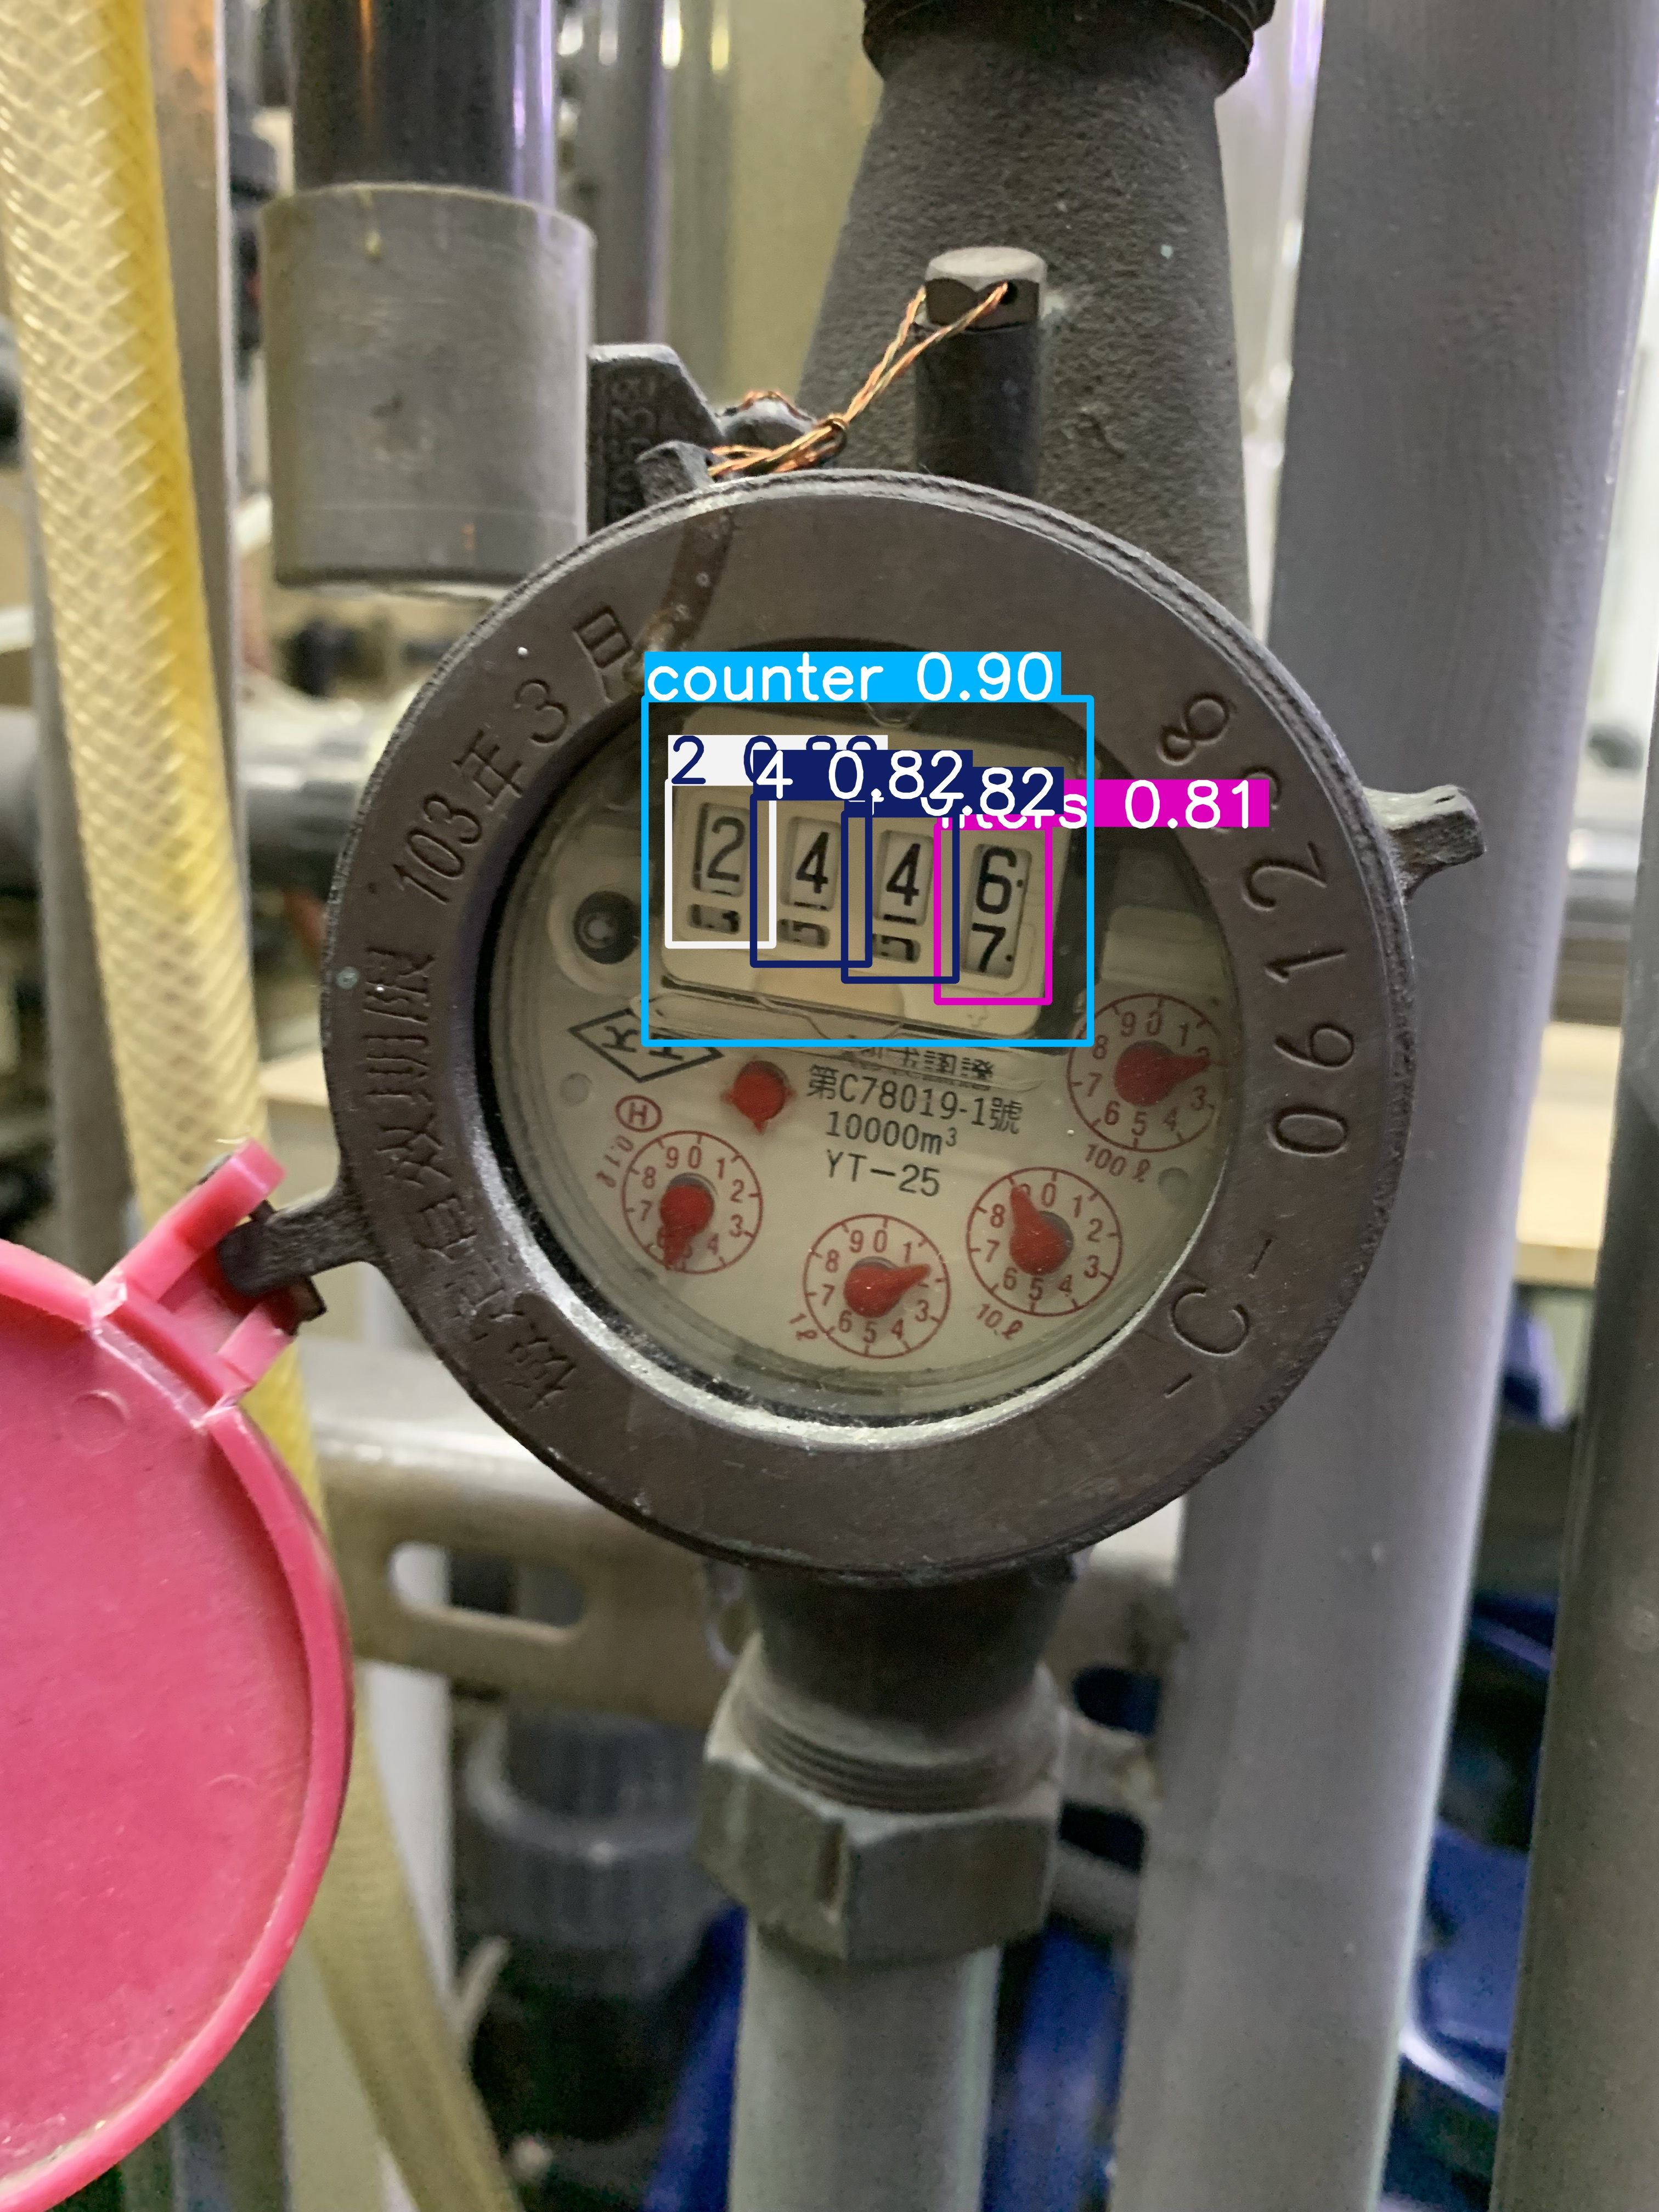

Результаты сохранены в:
/content/runs/watermeter/internet_predictions


In [14]:
from ultralytics import YOLO
from pathlib import Path
from IPython.display import display, Image

model = YOLO(
    "/content/runs/watermeter/yolo11m/weights/best.pt"
)

IMAGE_DIR = Path("/content/internet_images")

results = model.predict(
    source=str(IMAGE_DIR),
    imgsz=640,
    conf=0.25,
    save=True,
    project="/content/runs/watermeter",
    name="internet_predictions",
    exist_ok=True
)

# Показать результаты обнаружения
for result in results:
    plotted = result.plot()

    display(
        Image(
            data=__import__("cv2").imencode(
                ".jpg", plotted
            )[1].tobytes()
        )
    )

print("Результаты сохранены в:")
print("/content/runs/watermeter/internet_predictions")